In [1]:
pip install nltk


[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install pandas


[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install matplotlib


[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install seaborn


[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
import nltk
import re
import string
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet
# Download required NLTK data (uncomment when running first time)
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('vader_lexicon')
print("Libraries imported successfully!")

Libraries imported successfully!


[nltk_data] Downloading package punkt to /Users/vishal/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/vishal/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/vishal/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /Users/vishal/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/vishal/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [6]:
# Sample text data for preprocessing
sample_texts = [
 "I loved the movie! The acting was great and the plot was amazing!!!",
 "The product is okay, but not worth the price. Delivery was slow :(",
 "This is the worst experience ever!!! I want a refund immediately.",
 "Neutral review. Nothing special, but nothing terrible either.",
 "NLP is fascinating! It helps computers understand human language."
]
print("Original Texts:")
for i, text in enumerate(sample_texts):
 print(f"{i+1}. {text}")

Original Texts:
1. I loved the movie! The acting was great and the plot was amazing!!!
2. The product is okay, but not worth the price. Delivery was slow :(
3. This is the worst experience ever!!! I want a refund immediately.
4. Neutral review. Nothing special, but nothing terrible either.
5. NLP is fascinating! It helps computers understand human language.


In [7]:
def preprocess_text(text):
    """Preprocess text by:
 1. Converting to lowercase
 2. Removing punctuation
 3. Removing numbers
 4. Removing extra whitespace
 5. Removing URLs
 6. Removing HTML tags
 """
 # Convert to lowercase
    text = text.lower()
    # Remove URLs
    text = re.sub(r'http\S+', '', text)
    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Remove numbers
    text = re.sub(r'\d+', '', text)
    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text
    # Apply text cleaning
cleaned_texts = [preprocess_text(text) for text in sample_texts]
print("\nCleaned Texts:")
for i, text in enumerate(cleaned_texts):
    print(f"{i+1}. {text}")


Cleaned Texts:
1. i loved the movie the acting was great and the plot was amazing
2. the product is okay but not worth the price delivery was slow
3. this is the worst experience ever i want a refund immediately
4. neutral review nothing special but nothing terrible either
5. nlp is fascinating it helps computers understand human language


In [8]:
# Tokenize the cleaned texts (word tokenization)
word_tokenized_texts = [word_tokenize(text) for text in cleaned_texts]
print("\nWord Tokenized Texts:")
for i, tokens in enumerate(word_tokenized_texts):
 print(f"{i+1}. {tokens}")
# Sentence tokenization example
sample_paragraph = "NLP is amazing. It helps computers understand human language. This is a tutorial."
sentences = sent_tokenize(sample_paragraph)
print("\nSentence Tokenization:")
for i, sentence in enumerate(sentences):
 print(f"{i+1}. {sentence}")


Word Tokenized Texts:
1. ['i', 'loved', 'the', 'movie', 'the', 'acting', 'was', 'great', 'and', 'the', 'plot', 'was', 'amazing']
2. ['the', 'product', 'is', 'okay', 'but', 'not', 'worth', 'the', 'price', 'delivery', 'was', 'slow']
3. ['this', 'is', 'the', 'worst', 'experience', 'ever', 'i', 'want', 'a', 'refund', 'immediately']
4. ['neutral', 'review', 'nothing', 'special', 'but', 'nothing', 'terrible', 'either']
5. ['nlp', 'is', 'fascinating', 'it', 'helps', 'computers', 'understand', 'human', 'language']

Sentence Tokenization:
1. NLP is amazing.
2. It helps computers understand human language.
3. This is a tutorial.


In [9]:
# Get English stopwords
stop_words = set(stopwords.words('english'))
# Remove stopwords
filtered_texts = []
for tokens in word_tokenized_texts:
 filtered_tokens = [word for word in tokens if word not in stop_words]
 filtered_texts.append(filtered_tokens)
print("\nTexts after Stopword Removal:")
for i, tokens in enumerate(filtered_texts):
 print(f"{i+1}. {tokens}")



Texts after Stopword Removal:
1. ['loved', 'movie', 'acting', 'great', 'plot', 'amazing']
2. ['product', 'okay', 'worth', 'price', 'delivery', 'slow']
3. ['worst', 'experience', 'ever', 'want', 'refund', 'immediately']
4. ['neutral', 'review', 'nothing', 'special', 'nothing', 'terrible', 'either']
5. ['nlp', 'fascinating', 'helps', 'computers', 'understand', 'human', 'language']


In [10]:
import ssl
import certifi
import nltk

ssl._create_default_https_context = lambda: ssl.create_default_context(
    cafile=certifi.where()
)

nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/vishal/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [11]:
# Initialize stemmer and lemmatizer
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
# Function to get WordNet POS tag
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN
# Apply stemming
stemmed_texts = []
for tokens in filtered_texts:
    stemmed_tokens = [stemmer.stem(token) for token in tokens]
    stemmed_texts.append(stemmed_tokens)
print("\nStemmed Texts:")
for i, tokens in enumerate(stemmed_texts):
    print(f"{i+1}. {tokens}")
# Apply lemmatization with POS tagging
lemmatized_texts = []
for tokens in filtered_texts:
    pos_tags = pos_tag(tokens)
    lemmatized_tokens = []
    for word, tag in pos_tags:
        pos = get_wordnet_pos(tag)
        lemmatized_tokens.append(lemmatizer.lemmatize(word, pos=pos))
    lemmatized_texts.append(lemmatized_tokens)
print("\nLemmatized Texts:")
for i, tokens in enumerate(lemmatized_texts):
    print(f"{i+1}. {tokens}")


Stemmed Texts:
1. ['love', 'movi', 'act', 'great', 'plot', 'amaz']
2. ['product', 'okay', 'worth', 'price', 'deliveri', 'slow']
3. ['worst', 'experi', 'ever', 'want', 'refund', 'immedi']
4. ['neutral', 'review', 'noth', 'special', 'noth', 'terribl', 'either']
5. ['nlp', 'fascin', 'help', 'comput', 'understand', 'human', 'languag']

Lemmatized Texts:
1. ['love', 'movie', 'act', 'great', 'plot', 'amaze']
2. ['product', 'okay', 'worth', 'price', 'delivery', 'slow']
3. ['bad', 'experience', 'ever', 'want', 'refund', 'immediately']
4. ['neutral', 'review', 'nothing', 'special', 'nothing', 'terrible', 'either']
5. ['nlp', 'fascinate', 'help', 'computer', 'understand', 'human', 'language']


In [12]:
import sklearn

print(sklearn.__version__)

1.9.0


In [13]:
pip install sklearn

  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Preparing metadata (setup.py) ... error
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
    

In [14]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

preprocessed_texts = [' '.join(tokens) for tokens in lemmatized_texts]

count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(preprocessed_texts)

print("BoW shape:", bow_matrix.shape)

BoW shape: (5, 31)


In [15]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Reconstruct text from tokens for vectorization
preprocessed_texts = [' '.join(tokens) for tokens in lemmatized_texts]

# Bag of Words vectorization

In [16]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
# Reconstruct text from tokens for vectorization
preprocessed_texts = [' '.join(tokens) for tokens in lemmatized_texts]
# Bag of Words vectorization
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(preprocessed_texts)
print("\nBag of Words Matrix:")
print(bow_matrix.toarray())
print("Feature names:", count_vectorizer.get_feature_names_out())
# TF-IDF vectorization
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(preprocessed_texts)
print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray())
print("Feature names:", tfidf_vectorizer.get_feature_names_out())


Bag of Words Matrix:
[[1 1 0 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 1 0 0 0 0 1]
 [0 0 1 0 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0]
 [0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 2 0 0 0 0 0 1 0 1 1 0 0 0]
 [0 0 0 1 0 0 0 0 1 0 1 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0]]
Feature names: ['act' 'amaze' 'bad' 'computer' 'delivery' 'either' 'ever' 'experience'
 'fascinate' 'great' 'help' 'human' 'immediately' 'language' 'love'
 'movie' 'neutral' 'nlp' 'nothing' 'okay' 'plot' 'price' 'product'
 'refund' 'review' 'slow' 'special' 'terrible' 'understand' 'want' 'worth']

TF-IDF Matrix:
[[0.40824829 0.40824829 0.         0.         0.         0.
  0.         0.         0.         0.40824829 0.         0.
  0.         0.         0.40824829 0.40824829 0.         0.
  0.         0.         0.40824829 0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.        ]
 [0.         0.         

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

data = {
    'text' : [
        "I love this product, it's amazing!",
        "This is the worst purchase I've ever made",
        "Great quality and fast shipping",
        "Poor customer service and defective product",
        "Average product, nothing special",
        "Excellent value for money",
        "Terrible experience, would not recommend",
        "Okay product but overpriced",
        "Outstanding performance and durability",
        "Complete waste of money",
        "Best decision I've made this year",
        "Not satisfied with the quality",
        "Highly recommended to everyone",
        "Disappointing results",
        "Beyond my expectations"
    ],
    'label': [1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1]
}

df = pd.DataFrame(data)
print("Dataset for Classification:")
df.head(15)

Dataset for Classification:


,text,label
0,"I love this product, it's amazing!",1
1,This is the worst purchase I've ever made,0
2,Great quality and fast shipping,1
3,Poor customer service and defective product,0
4,"Average product, nothing special",1
5,Excellent value for money,1
6,"Terrible experience, would not recommend",0
7,Okay product but overpriced,0
8,Outstanding performance and durability,1
9,Complete waste of money,0


In [20]:
df['processed_text'] = df['text'].apply(preprocess_text)
def tokenize_and_remove_stopwords(text):
    tokens = word_tokenize(text)
    filtered_tokens = [word for word in tokens if word not in stop_words]
    return ' '.join(filtered_tokens)

df['processed_text'] = df['processed_text'].apply(tokenize_and_remove_stopwords)

print("\nProcessed Dataset:")
df[['text', 'processed_text', 'label']].head(15)


Processed Dataset:


,text,processed_text,label
0,"I love this product, it's amazing!",love product amazing,1
1,This is the worst purchase I've ever made,worst purchase ive ever made,0
2,Great quality and fast shipping,great quality fast shipping,1
3,Poor customer service and defective product,poor customer service defective product,0
4,"Average product, nothing special",average product nothing special,1
5,Excellent value for money,excellent value money,1
6,"Terrible experience, would not recommend",terrible experience would recommend,0
7,Okay product but overpriced,okay product overpriced,0
8,Outstanding performance and durability,outstanding performance durability,1
9,Complete waste of money,complete waste money,0


Training set size: (10, 34)
Test set size: (5, 34)

Logistic Regression Accuracy: 0.40
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.40      1.00      0.57         2

    accuracy                           0.40         5
   macro avg       0.20      0.50      0.29         5
weighted avg       0.16      0.40      0.23         5


Multinomial Naive Bayes Accuracy: 0.40
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.40      1.00      0.57         2

    accuracy                           0.40         5
   macro avg       0.20      0.50      0.29         5
weighted avg       0.16      0.40      0.23         5


Support Vector Machine Accuracy: 0.20
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.25      0.50      0.33         2

    accuracy    

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

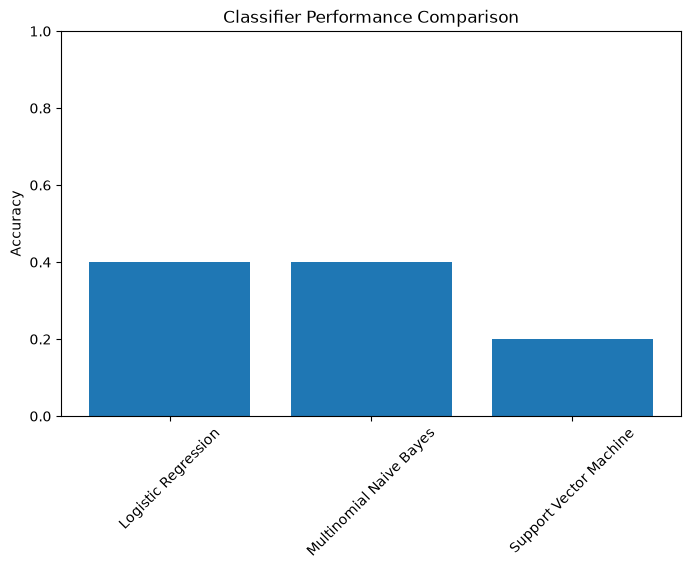

In [24]:
X = df['processed_text']
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(f"Training set size: {X_train_vec.shape}")
print(f"Test set size: {X_test_vec.shape}")

classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=200),
    'Multinomial Naive Bayes' : MultinomialNB(),
    'Support Vector Machine' : SVC(kernel='linear')
}

results = {}
for name, clf in classifiers.items():
    clf.fit(X_train_vec, y_train)
    y_pred = clf.predict(X_test_vec)
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy
    print(f"\n{name} Accuracy: {accuracy:.2f}")
    print(classification_report(y_test,y_pred))

# Plot comparison
plt.figure(figsize=(8, 5))
plt.bar(results.keys(), results.values())
plt.title('Classifier Performance Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.show()




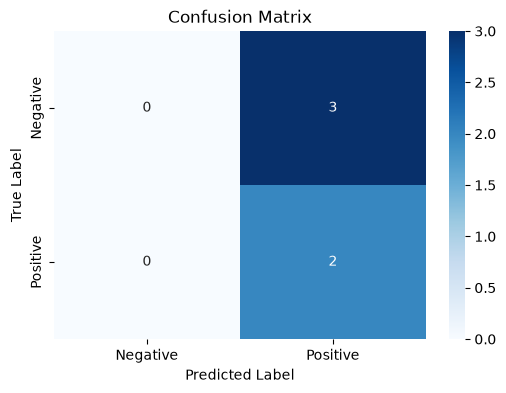

In [25]:
best_model = LogisticRegression(max_iter=200)
best_model.fit(X_train_vec, y_train)
y_pred = best_model.predict(X_test_vec)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
 xticklabels=['Negative', 'Positive'],
 yticklabels=['Negative', 'Positive'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()